In [1]:
!pip install scipy
!pip install statsmodels
!pip install scikit-learn

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
    --------------------------------------- 0.5/37.4 MB 478.3 kB/s eta 0:01:18
    --------------------------------------- 0.8/37.4 MB 823.7 kB/s eta 0:00:45
    --------------------------------------- 0.8/37.4 MB 823.7 kB/s eta 0:00:45
   - -------------------------------------- 1.3/37.4 MB 959.6 kB/s eta 0:00:38
   - -------------------------------------- 1.3/37.4 MB 959.6 kB/s eta 0:00:38
   - -------------------------------------- 1.6/37.4 MB 826.3 kB/s eta 0:00:44
   -- ------------------------------------- 2.1/37.4 MB 1.0 MB/s eta 0:00:35
   -- ------------------------------------- 2.1/37.4 MB 1.0 MB/s eta 0:00:35
   -- ------------------------------------- 2.4/37.4 MB 941.0 kB/s eta 0:00:38
   -- -------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -----------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 1.6 MB/s eta 0:00:05
   -- ------------------------------------- 0.5/8.4 MB 1.6 MB/s eta 0:00:05
   -- ------------------------------------- 0.5/8.4 MB 1.6 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/8.4 MB 694.7 kB/s eta 0:00:11
   ------ --------------------------------- 1.3/8.4 MB 1.0 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.4 MB 1.0 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.4 MB 1.0 MB/s eta 0:00:07
   ------- -------------------------------- 1.6/8.4 MB 843.1 kB/s eta 0:00:09
   ------- --------------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
EM_NOTEBOOK = "ipykernel" in sys.modules
if EM_NOTEBOOK:
    from IPython import get_ipython
    get_ipython().run_line_magic("matplotlib", "inline")
else:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
 
warnings.filterwarnings("ignore")
try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
GOLD = ROOT / "dados" / "gold" / "history_gold.csv"
SILVER = ROOT / "dados" / "silver" / "history_silver.csv"
OUT = ROOT / "graficos"
OUT.mkdir(exist_ok=True)
 
MOEDA = "R$"   # ajuste aqui se a moeda dos valores for outra
BLUE, RED, GRAY, GREEN, ORANGE, PURPLE = "#4C78A8", "#E45756", "#B0B7C3", "#54A24B", "#F58518", "#8E6BBE"
PAL = [BLUE, ORANGE, GREEN, RED, PURPLE, "#72B7B2", "#9D755D"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
 
 
def save(fig, name):
    fig.savefig(OUT / name, dpi=150, bbox_inches="tight", facecolor="white")
    if EM_NOTEBOOK:
        plt.show()
    plt.close(fig)
 
 
def pct(v, d=0):
    return f"{v:.{d}f}%"
 
 
# ------------------------------------------------------------------ dados
g = pd.read_csv(GOLD)
s = pd.read_csv(SILVER, usecols=["ID_Cliente", "Multiplas_Linhas", "Streaming_TV", "Streaming_Filmes"])
g = g.merge(s, on="ID_Cliente", how="left")
for c in ["Multiplas_Linhas", "Streaming_TV", "Streaming_Filmes"]:
    g[c] = (g[c] == "Yes").astype(int)
g["Contrato_PT"] = g.Contrato.map({"Month-to-month": "Mensal", "One year": "1 ano", "Two year": "2 anos"})
g["Internet_PT"] = g.Servico_Internet.map({"Fiber optic": "Fibra", "DSL": "DSL", "No": "Sem internet"})
g["Pagamento_PT"] = g.Metodo_Pagamento.map({
    "Electronic check": "Cheque eletrônico", "Mailed check": "Cheque correio",
    "Bank transfer (automatic)": "Transf. automática", "Credit card (automatic)": "Cartão automático"})
ORD_C, ORD_I = ["Mensal", "1 ano", "2 anos"], ["Fibra", "DSL", "Sem internet"]
ORD_P = ["Cheque eletrônico", "Cheque correio", "Transf. automática", "Cartão automático"]
ORD_F = ["0-6", "7-12", "13-24", "25-48", "48+"]
MRR = g.Cobranca_Mensal.sum()
net = g[g.Servico_Internet != "No"].copy()

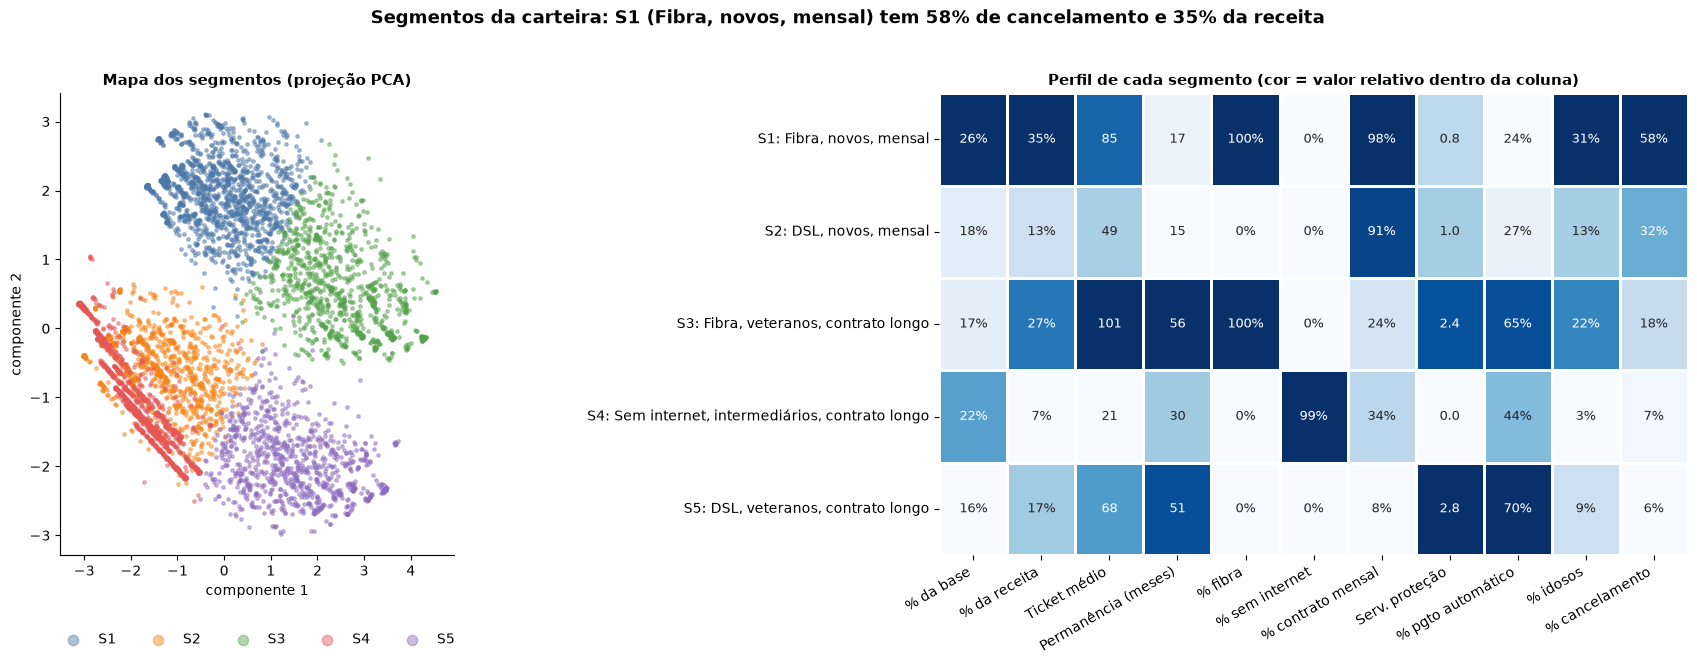

In [3]:
Z = pd.DataFrame({
    "ten": g.Tempo_Permanencia_Meses, "cob": g.Cobranca_Mensal, "prot": g.Qtd_Servicos_Protecao,
    "tot": g.Qtd_Servicos_Total, "fibra": (g.Internet_PT == "Fibra").astype(int),
    "dsl": (g.Internet_PT == "DSL").astype(int), "mensal": (g.Contrato_PT == "Mensal").astype(int),
    "pa": g.Pagamento_Automatico, "idoso": g.Cliente_Idoso, "fam": g.Tem_Familia}).astype(float)
Zs = StandardScaler().fit_transform(Z)
g["Cluster"] = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(Zs)   # o cancelamento NÃO entra na segmentação
 
 
def descreve(d):
    ten = d.Tempo_Permanencia_Meses.mean()
    t = "novos" if ten < 20 else ("intermediários" if ten < 40 else "veteranos")
    m = (d.Contrato_PT == "Mensal").mean()
    c = "mensal" if m > 0.6 else ("contrato longo" if m < 0.35 else "contrato misto")
    return f"{d.Internet_PT.mode()[0]}, {t}, {c}"
 
 
ordem = g.groupby("Cluster").Cancelou.mean().sort_values(ascending=False).index
nomes = {c: f"S{i + 1}: {descreve(g[g.Cluster == c])}" for i, c in enumerate(ordem)}
g["Segmento"] = g.Cluster.map(nomes)
seg = g.groupby("Segmento").agg(
    n=("ID_Cliente", "size"), receita=("Cobranca_Mensal", "sum"), ticket=("Cobranca_Mensal", "mean"),
    perm=("Tempo_Permanencia_Meses", "mean"), fibra=("Internet_PT", lambda v: (v == "Fibra").mean() * 100),
    semnet=("Internet_PT", lambda v: (v == "Sem internet").mean() * 100),
    mensal=("Contrato_PT", lambda v: (v == "Mensal").mean() * 100), prot=("Qtd_Servicos_Protecao", "mean"),
    pa=("Pagamento_Automatico", lambda v: v.mean() * 100), idoso=("Cliente_Idoso", lambda v: v.mean() * 100),
    churn=("Cancelou", lambda v: v.mean() * 100)).sort_index()
seg["pcli"], seg["prec"] = seg.n / len(g) * 100, seg.receita / MRR * 100
cols = [("pcli", "% da base", "{:.0f}%"), ("prec", "% da receita", "{:.0f}%"), ("ticket", "Ticket médio", "{:.0f}"),
        ("perm", "Permanência (meses)", "{:.0f}"), ("fibra", "% fibra", "{:.0f}%"), ("semnet", "% sem internet", "{:.0f}%"),
        ("mensal", "% contrato mensal", "{:.0f}%"), ("prot", "Serv. proteção", "{:.1f}"),
        ("pa", "% pgto automático", "{:.0f}%"), ("idoso", "% idosos", "{:.0f}%"), ("churn", "% cancelamento", "{:.0f}%")]
vals = seg[[c for c, _, _ in cols]]
norm = (vals - vals.min()) / (vals.max() - vals.min())
ann = pd.DataFrame({c: vals[c].map(f.format) for c, _, f in cols})
 
fig, axes = plt.subplots(1, 2, figsize=(21, 6), gridspec_kw={"width_ratios": [1, 1.9], "wspace": 0.85})
pc = PCA(2, random_state=0).fit_transform(Zs)
for i, nm in enumerate(seg.index):
    m = (g.Segmento == nm).values
    axes[0].scatter(pc[m, 0], pc[m, 1], s=6, alpha=0.45, color=PAL[i], label=nm.split(":")[0])
axes[0].set_title("Mapa dos segmentos (projeção PCA)")
axes[0].set_xlabel("componente 1")
axes[0].set_ylabel("componente 2")
axes[0].legend(markerscale=3, frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14))
sns.heatmap(norm, annot=ann, fmt="", cmap="Blues", cbar=False, linewidths=1, ax=axes[1], annot_kws={"size": 9})
axes[1].set_xticklabels([t for _, t, _ in cols], rotation=30, ha="right")
axes[1].set_ylabel("")
axes[1].set_title("Perfil de cada segmento (cor = valor relativo dentro da coluna)")
worst = seg.churn.idxmax()
fig.suptitle(f"Segmentos da carteira: {worst.split(':')[0]} ({worst.split(': ')[1]}) tem {seg.loc[worst, 'churn']:.0f}% de cancelamento "
             f"e {seg.loc[worst, 'prec']:.0f}% da receita", fontsize=13, fontweight="bold", y=1.02)
save(fig, "16_segmentos_da_carteira.png")

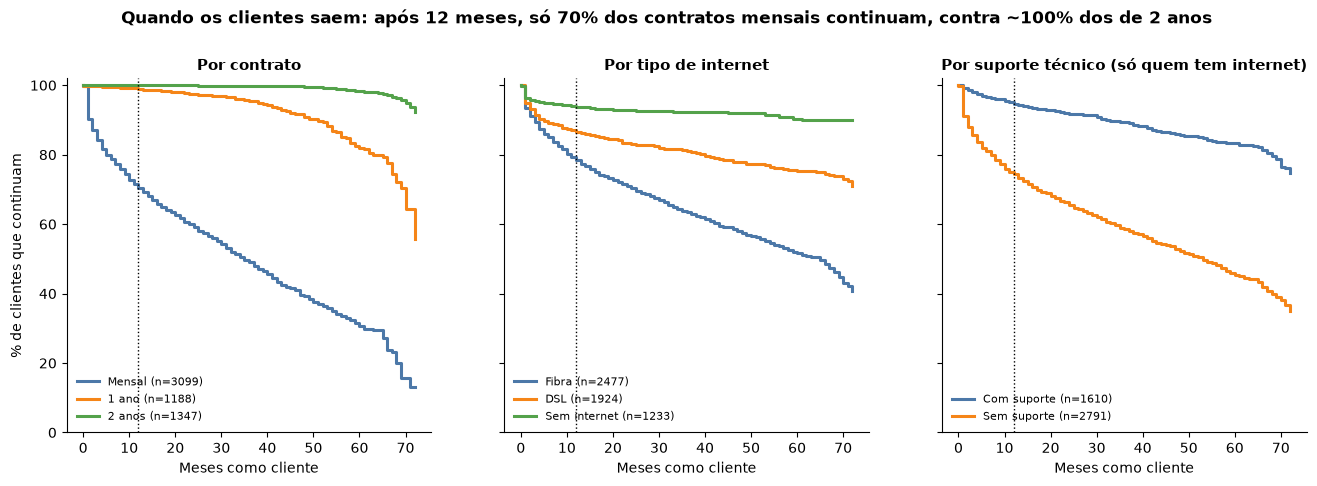

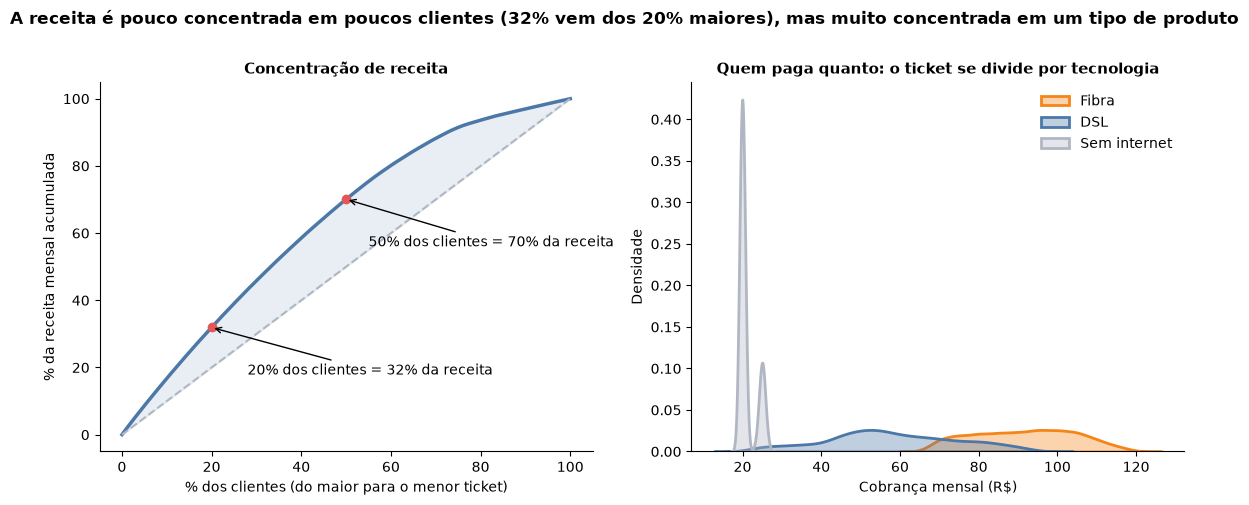

In [4]:
def km(dur, ev):
    d = pd.DataFrame({"t": dur.values, "e": ev.values}).groupby("t").agg(d=("e", "sum"), n=("e", "size"))
    risco = len(dur) - d.n.cumsum().shift(fill_value=0)
    surv = (1 - d.d / risco).cumprod()
    return np.r_[0, d.index.values], np.r_[1, surv.values]
 
 
def s_em(t, st, mes):
    return st[t <= mes][-1] * 100
 
 
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
net["Suporte"] = np.where(net.Suporte_Tecnico == 1, "Com suporte", "Sem suporte")
grupos = [(g, "Contrato_PT", ORD_C, "Por contrato"), (g, "Internet_PT", ORD_I, "Por tipo de internet"),
          (net, "Suporte", ["Com suporte", "Sem suporte"], "Por suporte técnico (só quem tem internet)")]
res17 = {}
for ax, (d, col, order, tit) in zip(axes, grupos):
    for i, k in enumerate(order):
        sub = d[d[col] == k]
        t, st = km(sub.Tempo_Permanencia_Meses, sub.Cancelou)
        ax.step(t, st * 100, where="post", color=PAL[i], lw=2.2, label=f"{k} (n={len(sub)})")
        res17[(col, k)] = s_em(t, st, 12)
    ax.axvline(12, color="k", ls=":", lw=1)
    ax.set_title(tit)
    ax.set_xlabel("Meses como cliente")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    ax.set_ylim(0, 102)
axes[0].set_ylabel("% de clientes que continuam")
fig.suptitle(f"Quando os clientes saem: após 12 meses, só {res17[('Contrato_PT', 'Mensal')]:.0f}% dos contratos mensais continuam, "
             f"contra ~{res17[('Contrato_PT', '2 anos')]:.0f}% dos de 2 anos", fontsize=12, fontweight="bold", y=1.03)
save(fig, "17_curva_de_permanencia.png")
 
# ================================================================== 18. concentração de receita
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
srt = g.Cobranca_Mensal.sort_values(ascending=False).reset_index(drop=True)
x = np.arange(1, len(srt) + 1) / len(srt) * 100
cum = srt.cumsum() / srt.sum() * 100
axes[0].plot(x, cum, color=BLUE, lw=2.5)
axes[0].plot([0, 100], [0, 100], color=GRAY, ls="--")
axes[0].fill_between(x, cum, x, color=BLUE, alpha=0.12)
top20 = cum[int(len(srt) * 0.2) - 1]
top50 = cum[int(len(srt) * 0.5) - 1]
axes[0].scatter([20, 50], [top20, top50], color=RED, zorder=3)
axes[0].annotate(f"20% dos clientes = {top20:.0f}% da receita", (20, top20), xytext=(28, top20 - 14), arrowprops=dict(arrowstyle="->"))
axes[0].annotate(f"50% dos clientes = {top50:.0f}% da receita", (50, top50), xytext=(55, top50 - 14), arrowprops=dict(arrowstyle="->"))
axes[0].set_xlabel("% dos clientes (do maior para o menor ticket)")
axes[0].set_ylabel("% da receita mensal acumulada")
axes[0].set_title("Concentração de receita")
for i, k in enumerate(ORD_I):
    sns.kdeplot(g[g.Internet_PT == k].Cobranca_Mensal, fill=True, alpha=0.35, color=[ORANGE, BLUE, GRAY][i], label=k, ax=axes[1], lw=2)
axes[1].set_xlabel(f"Cobrança mensal ({MOEDA})")
axes[1].set_ylabel("Densidade")
axes[1].set_title("Quem paga quanto: o ticket se divide por tecnologia")
axes[1].legend(frameon=False)
fig.suptitle(f"A receita é pouco concentrada em poucos clientes ({top20:.0f}% vem dos 20% maiores), mas muito concentrada em um tipo de produto",
             fontsize=12, fontweight="bold", y=1.03)
save(fig, "18_concentracao_de_receita.png")

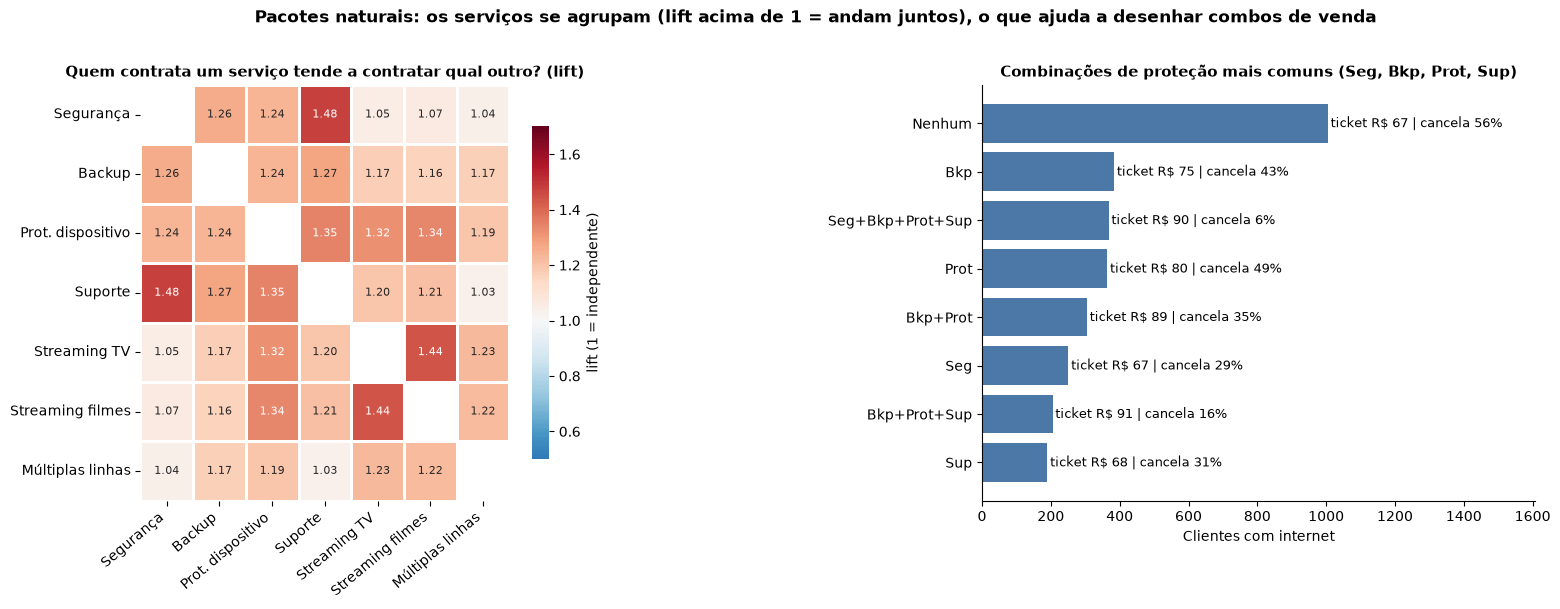

In [5]:
SERV = {"Seguranca_Online": "Segurança", "Backup_Online": "Backup", "Protecao_Dispositivo": "Prot. dispositivo",
        "Suporte_Tecnico": "Suporte", "Streaming_TV": "Streaming TV", "Streaming_Filmes": "Streaming filmes",
        "Multiplas_Linhas": "Múltiplas linhas"}
B = net[list(SERV)].astype(float)
p = B.mean()
lift = pd.DataFrame({a: {b: (B[a] * B[b]).mean() / (p[a] * p[b]) for b in SERV} for a in SERV}).rename(index=SERV, columns=SERV)
lift = lift.mask(np.eye(len(lift), dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(18, 5.4), gridspec_kw={"width_ratios": [1, 1.2], "wspace": 0.75})
sns.heatmap(lift, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.5, vmax=1.7, linewidths=1, ax=axes[0],
            cbar_kws={"label": "lift (1 = independente)", "shrink": 0.8}, annot_kws={"size": 8})
axes[0].set_title("Quem contrata um serviço tende a contratar qual outro? (lift)")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=40, ha="right")
abrev = {"Seguranca_Online": "Seg", "Backup_Online": "Bkp", "Protecao_Dispositivo": "Prot", "Suporte_Tecnico": "Sup"}
net["Combo"] = net[list(abrev)].apply(lambda r: "+".join(abrev[c] for c in abrev if r[c] == 1) or "Nenhum", axis=1)
cb = net.groupby("Combo").agg(n=("ID_Cliente", "size"), ticket=("Cobranca_Mensal", "mean"), churn=("Cancelou", "mean")).sort_values("n", ascending=False).head(8)
cb = cb.iloc[::-1]
axes[1].barh(cb.index, cb.n, color=BLUE)
for i, (n_, t_, c_) in enumerate(zip(cb.n, cb.ticket, cb.churn)):
    axes[1].text(n_ + 8, i, f"ticket {MOEDA} {t_:.0f} | cancela {c_ * 100:.0f}%", va="center", fontsize=9)
axes[1].set_xlim(0, cb.n.max() * 1.6)
axes[1].set_xlabel("Clientes com internet")
axes[1].set_title("Combinações de proteção mais comuns (Seg, Bkp, Prot, Sup)")
mx = lift.stack().sort_values(ascending=False)
fig.suptitle("Pacotes naturais: os serviços se agrupam (lift acima de 1 = andam juntos), o que ajuda a desenhar combos de venda",
             fontsize=12, fontweight="bold", y=1.02)
save(fig, "19_afinidade_entre_servicos.png")

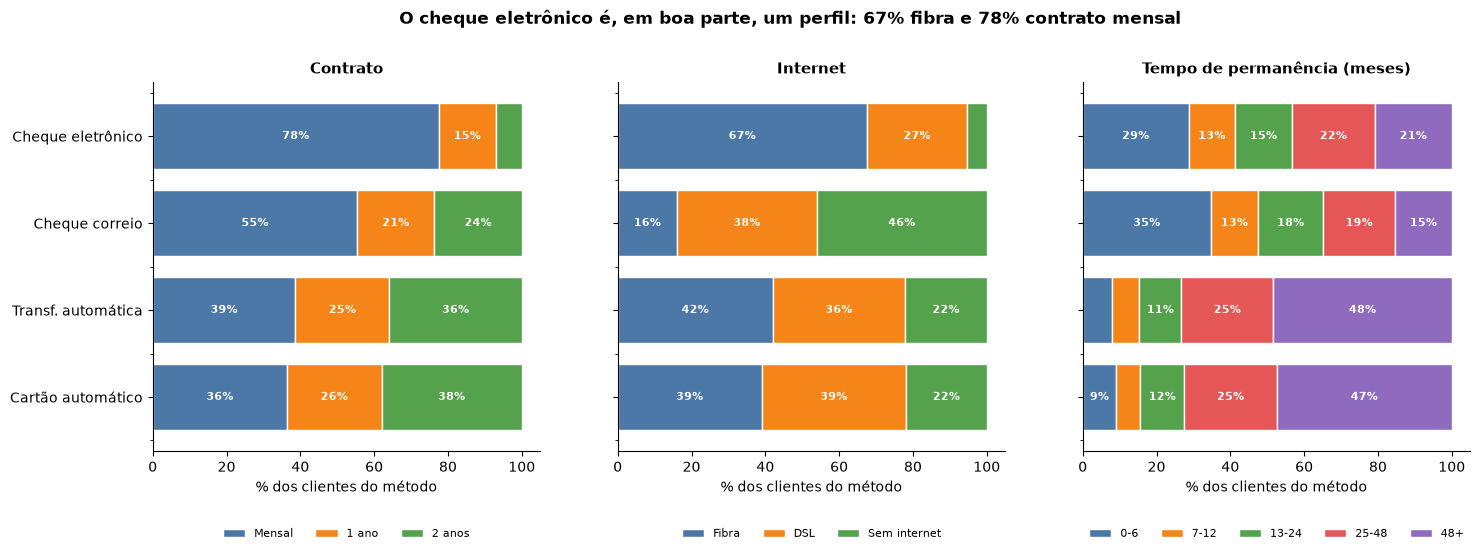

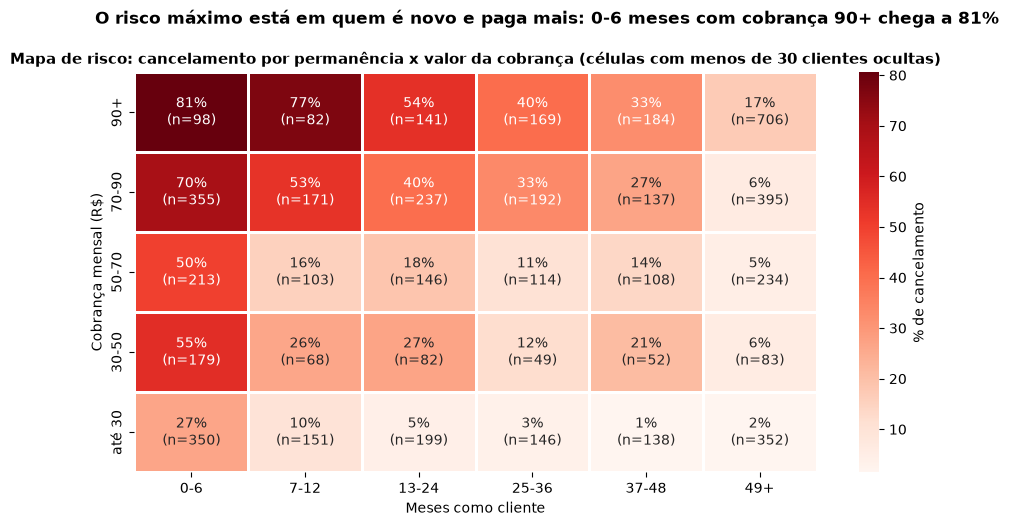

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, (col, order, tit) in zip(axes, [("Contrato_PT", ORD_C, "Contrato"), ("Internet_PT", ORD_I, "Internet"),
                                        ("Faixa_Permanencia", ORD_F, "Tempo de permanência (meses)")]):
    ct = pd.crosstab(g.Pagamento_PT, g[col], normalize="index").loc[ORD_P, order] * 100
    ct.plot.barh(stacked=True, ax=ax, color=PAL[:len(order)], width=0.75, edgecolor="white")
    for j, (_, row) in enumerate(ct.iterrows()):
        left = 0
        for v in row:
            if v > 8:
                ax.text(left + v / 2, j, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
            left += v
    ax.set_title(tit)
    ax.set_xlabel("% dos clientes do método")
    ax.set_ylabel("")
    ax.legend(frameon=False, fontsize=8, ncol=len(order), loc="upper center", bbox_to_anchor=(0.5, -0.18))
    ax.invert_yaxis()
ce = g[g.Pagamento_PT == "Cheque eletrônico"]
fig.suptitle(f"O cheque eletrônico é, em boa parte, um perfil: {(ce.Internet_PT == 'Fibra').mean() * 100:.0f}% fibra e "
             f"{(ce.Contrato_PT == 'Mensal').mean() * 100:.0f}% contrato mensal", fontsize=12, fontweight="bold", y=1.03)
save(fig, "20_perfil_por_pagamento.png")
 
# ================================================================== 21. mapa de risco: permanência x cobrança
g["Faixa_Cobranca"] = pd.cut(g.Cobranca_Mensal, [0, 30, 50, 70, 90, 200], labels=["até 30", "30-50", "50-70", "70-90", "90+"])
g["Faixa_Perm2"] = pd.cut(g.Tempo_Permanencia_Meses, [-1, 6, 12, 24, 36, 48, 100], labels=["0-6", "7-12", "13-24", "25-36", "37-48", "49+"])
mc = g.pivot_table(index="Faixa_Cobranca", columns="Faixa_Perm2", values="Cancelou", aggfunc="mean").mul(100)
mn = g.pivot_table(index="Faixa_Cobranca", columns="Faixa_Perm2", values="Cancelou", aggfunc="size")
lab = mc.round(0).astype("Int64").astype(str) + "%\n(n=" + mn.astype(str) + ")"
lab = lab.where(mn >= 30, "")
fig, ax = plt.subplots(figsize=(11, 5.2))
sns.heatmap(mc.where(mn >= 30), annot=lab, fmt="", cmap="Reds", linewidths=1, ax=ax, cbar_kws={"label": "% de cancelamento"})
ax.invert_yaxis()
ax.set_xlabel("Meses como cliente")
ax.set_ylabel(f"Cobrança mensal ({MOEDA})")
ax.set_title("Mapa de risco: cancelamento por permanência x valor da cobrança (células com menos de 30 clientes ocultas)")
hi = mc.where(mn >= 30).stack().idxmax()
fig.suptitle(f"O risco máximo está em quem é novo e paga mais: {hi[1]} meses com cobrança {hi[0]} chega a {mc.loc[hi]:.0f}%",
             fontsize=12, fontweight="bold", y=1.0)
save(fig, "21_mapa_de_risco.png")

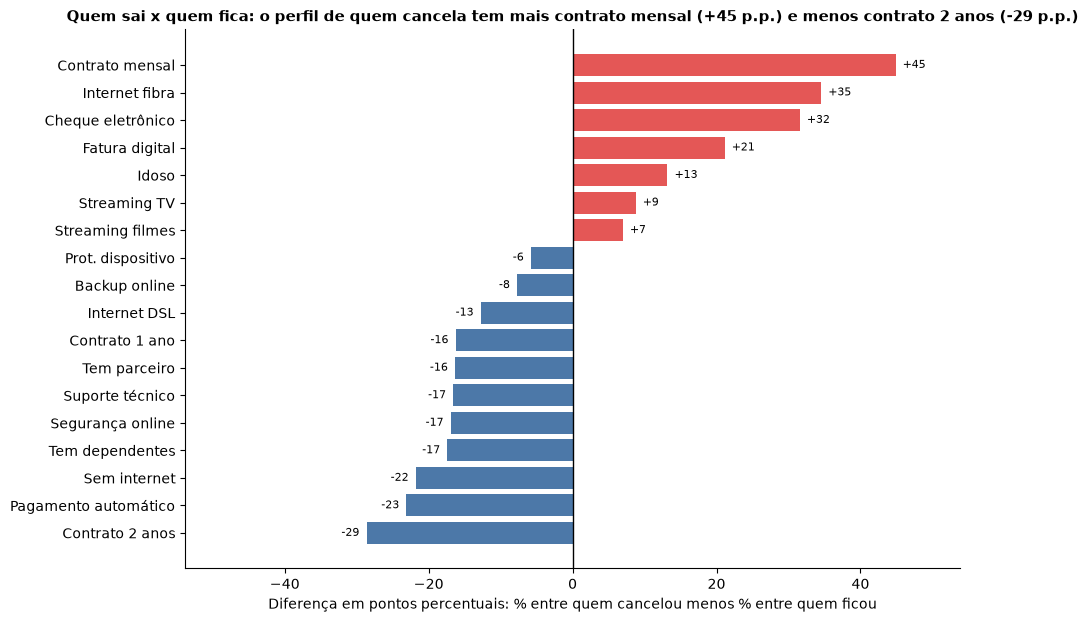

In [7]:
fl = {"Idoso": g.Cliente_Idoso, "Tem parceiro": g.Parceiro, "Tem dependentes": g.Dependentes,
      "Fatura digital": g.Faturamento_Sem_Papel, "Pagamento automático": g.Pagamento_Automatico,
      "Segurança online": g.Seguranca_Online, "Backup online": g.Backup_Online,
      "Prot. dispositivo": g.Protecao_Dispositivo, "Suporte técnico": g.Suporte_Tecnico,
      "Streaming TV": g.Streaming_TV, "Streaming filmes": g.Streaming_Filmes,
      "Contrato mensal": (g.Contrato_PT == "Mensal").astype(int), "Contrato 1 ano": (g.Contrato_PT == "1 ano").astype(int),
      "Contrato 2 anos": (g.Contrato_PT == "2 anos").astype(int), "Internet fibra": (g.Internet_PT == "Fibra").astype(int),
      "Internet DSL": (g.Internet_PT == "DSL").astype(int), "Sem internet": (g.Internet_PT == "Sem internet").astype(int),
      "Cheque eletrônico": (g.Pagamento_PT == "Cheque eletrônico").astype(int)}
dif = pd.Series({k: (v[g.Cancelou == 1].mean() - v[g.Cancelou == 0].mean()) * 100 for k, v in fl.items()}).sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(dif.index, dif.values, color=[RED if v > 0 else BLUE for v in dif.values])
for i, v in enumerate(dif.values):
    ax.text(v + (1 if v > 0 else -1), i, f"{v:+.0f}", va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Diferença em pontos percentuais: % entre quem cancelou menos % entre quem ficou")
ax.set_title(f"Quem sai x quem fica: o perfil de quem cancela tem mais {dif.index[-1].lower()} ({dif.iloc[-1]:+.0f} p.p.) "
             f"e menos {dif.index[0].lower()} ({dif.iloc[0]:+.0f} p.p.)")
xl = max(abs(dif.min()), abs(dif.max())) * 1.2
ax.set_xlim(-xl, xl)
save(fig, "22_perfil_quem_sai_x_quem_fica.png")

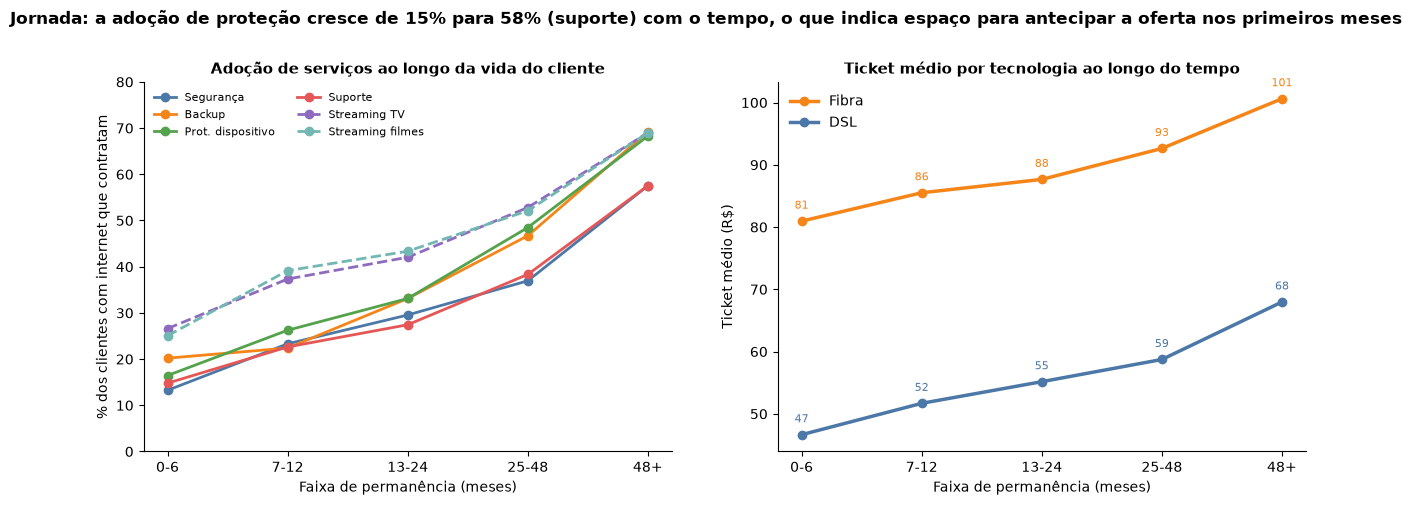

ok ['16_segmentos_da_carteira.png', '17_curva_de_permanencia.png', '18_concentracao_de_receita.png', '19_afinidade_entre_servicos.png', '20_perfil_por_pagamento.png', '21_mapa_de_risco.png', '22_perfil_quem_sai_x_quem_fica.png', '23_jornada_do_cliente.png']
                                                     n  pcli  prec  ticket  perm  fibra  mensal  churn
Segmento                                                                                              
S1: Fibra, novos, mensal                          1490  26.4  34.8    85.0  17.4  100.0    98.3   57.9
S2: DSL, novos, mensal                             990  17.6  13.2    48.6  14.8    0.0    91.3   32.1
S3: Fibra, veteranos, contrato longo               984  17.5  27.4   101.3  56.3  100.0    23.8   18.3
S4: Sem internet, intermediários, contrato longo  1242  22.0   7.3    21.3  30.3    0.2    33.7    7.2
S5: DSL, veteranos, contrato longo                 928  16.5  17.3    67.9  51.4    0.0     8.4    5.8


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ad = net.groupby("Faixa_Permanencia")[["Seguranca_Online", "Backup_Online", "Protecao_Dispositivo", "Suporte_Tecnico",
                                       "Streaming_TV", "Streaming_Filmes"]].mean().reindex(ORD_F) * 100
nm = {"Seguranca_Online": "Segurança", "Backup_Online": "Backup", "Protecao_Dispositivo": "Prot. dispositivo",
      "Suporte_Tecnico": "Suporte", "Streaming_TV": "Streaming TV", "Streaming_Filmes": "Streaming filmes"}
for i, c in enumerate(ad.columns):
    axes[0].plot(ORD_F, ad[c], marker="o", lw=2, color=PAL[i], label=nm[c], ls="--" if "Streaming" in nm[c] else "-")
axes[0].set_ylim(0, 80)
axes[0].set_xlabel("Faixa de permanência (meses)")
axes[0].set_ylabel("% dos clientes com internet que contratam")
axes[0].set_title("Adoção de serviços ao longo da vida do cliente")
axes[0].legend(frameon=False, fontsize=8, ncol=2)
tk = g.pivot_table(index="Faixa_Permanencia", columns="Internet_PT", values="Cobranca_Mensal", aggfunc="mean").reindex(ORD_F)[["Fibra", "DSL"]]
for i, c in enumerate(["Fibra", "DSL"]):
    axes[1].plot(ORD_F, tk[c], marker="o", lw=2.5, color=[ORANGE, BLUE][i], label=c)
    for j, v in enumerate(tk[c]):
        axes[1].text(j, v + 2, f"{v:.0f}", ha="center", fontsize=8, color=[ORANGE, BLUE][i])
axes[1].set_xlabel("Faixa de permanência (meses)")
axes[1].set_ylabel(f"Ticket médio ({MOEDA})")
axes[1].set_title("Ticket médio por tecnologia ao longo do tempo")
axes[1].legend(frameon=False)
fig.suptitle(f"Jornada: a adoção de proteção cresce de {ad.Suporte_Tecnico['0-6']:.0f}% para {ad.Suporte_Tecnico['48+']:.0f}% (suporte) "
             "com o tempo, o que indica espaço para antecipar a oferta nos primeiros meses", fontsize=12, fontweight="bold", y=1.03)
save(fig, "23_jornada_do_cliente.png")
 
print("ok", sorted(p.name for p in OUT.glob("*.png") if p.name[:2] in {str(i) for i in range(16, 24)}))
show = seg[["n", "pcli", "prec", "ticket", "perm", "fibra", "mensal", "churn"]].round(1)
print(show.to_string())